Dataset Shape: (3329, 95)

First 5 Rows:
   Gender    Age Online purchase frequency       Academic Qualification  \
0  Female  23-28                      1-10  Doctrate (even if pursuing)   
1    Male  23-28                      1-10                Post Graduate   
2  Female  17-22                      1-10                Post Graduate   
3  Female  17-22                      1-10                Post Graduate   
4  Female  17-22                      1-10                Post Graduate   

        Type of University  Products purchased in past year(Multiple answers)  \
0  Deemed to be University                                       All products   
1         State University                      Electronic goods(Mobiles etc)   
2         State University  Electronic goods(Mobiles etc), Clothing/Shoes/...   
3         State University                     Clothing/Shoes/Beauty products   
4         State University                     Clothing/Shoes/Beauty products   

  Money spent on thes

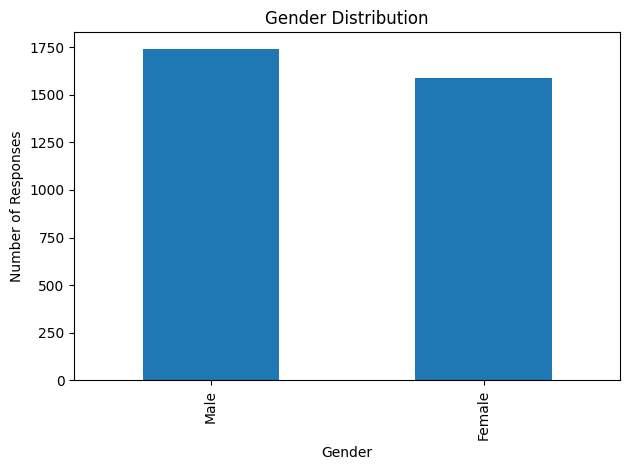


Online Shopping Frequency:
Online purchase frequency
11-20                        1621
1-10                          967
21-30                         579
Once last year                133
Just surf and buy nothing      29
Name: count, dtype: int64

Website Design Ratings:
I make a purchase from website(s) on the basis of its design and graphics (colors,layout and images etc.).
1      62
2     121
3     355
4    1323
5    1468
Name: count, dtype: int64
Ratings of 4 or 5: 83.8%


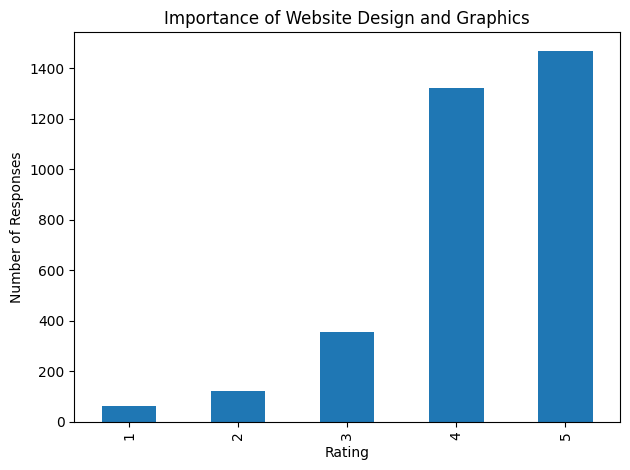


NOTE: Duplicate rows require investigation. Results are preliminary and should not be treated as final.


In [1]:
# Student Buying Behaviour Analysis
# Exploratory Data Analysis (EDA)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Load dataset
file_path = "consumerresponses.xlsx"
df = pd.read_excel(file_path, sheet_name="Form responses 1")

# 1. Dataset overview
print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
print(df.head())

# 2. Data quality check
print("\nMissing Values:", df.isnull().sum().sum())
print("Exact Duplicate Rows:", df.duplicated().sum())
print("Unique Rows:", len(df.drop_duplicates()))

# 3. Gender distribution
if "Gender" in df.columns:
    print("\nGender Distribution:")
    print(df["Gender"].value_counts())

    df["Gender"].value_counts().plot(kind="bar")
    plt.title("Gender Distribution")
    plt.xlabel("Gender")
    plt.ylabel("Number of Responses")
    plt.tight_layout()
    plt.show()

# 4. Online shopping frequency
frequency_col = "Online purchase frequency"

if frequency_col in df.columns:
    print("\nOnline Shopping Frequency:")
    print(df[frequency_col].value_counts())

# 5. Website design and graphics
design_col = next(
    (col for col in df.columns if "design and graphics" in col.lower()),
    None
)

if design_col:
    ratings = pd.to_numeric(df[design_col], errors="coerce")
    valid_ratings = ratings.dropna()

    print("\nWebsite Design Ratings:")
    print(valid_ratings.value_counts().sort_index())

    high_ratings = valid_ratings.isin([4, 5]).sum()
    percentage = high_ratings / len(valid_ratings) * 100

    print(f"Ratings of 4 or 5: {percentage:.1f}%")

    valid_ratings.value_counts().sort_index().plot(kind="bar")
    plt.title("Importance of Website Design and Graphics")
    plt.xlabel("Rating")
    plt.ylabel("Number of Responses")
    plt.tight_layout()
    plt.show()

# 6. Important note
print(
    "\nNOTE: Duplicate rows require investigation. "
    "Results are preliminary and should not be treated as final."
)